In [105]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Connect MCA, Don Bosco 1 Employer Survey, and LFS (ASPBI) Number of Employed

In [137]:
# clean mca
mca_df = pd.read_csv('data/final_mca_with_ai_measurements.csv')
mca_df['PSOC Code'] = mca_df['PSOC Code'].astype(str)

# clean db1 tvet
db1_tvet_df = pd.read_excel('data/DB1TVET_Employer_Survey.xlsx')
course_mapping = {
    "Agricultural Technology Servicing (ATS) NC II": "Agricultural Machinery Operation NC II",
    "Electrical Installation & Maintenance (EIM) NC II": "Electrical Installation and Maintenance NC II",
    "Machining NC II": "Machining NC I, Machining NC II, Machining NC III",
    "Shielded Metal Arc Welding (SMAW) NC II": "Manual Metal Arc Welding (MMAW) NC II",
    "Industrial Electricity / Electrician": "Electrical Installation and Maintenance NC II",
    "Motorcycle / Small Engine Servicing (MSES) NC II": "Motorcycle/Small Engine Servicing NC II",
    "Organic Agriculture Production (OAP) NC II": "Organic Agriculture Production NC II",
    "Automotive Servicing NC II": "Automotive Servicing (Chassis Repair) NC II",
    "Refrigeration & Air Conditioning (RAC) Servicing NC II": "RAC Servicing (DomRAC) NC II",
    "Bookkeeping (BK) NC III": "Bookkeeping NC III",
    "Agricultural Crop Production (ACP) NC II": "Coconut Production Level II, Agricultural Crops Production NC II",
    "Agricultural Entrepreneurship (AGE) NC II": "Agroentrepreneurship NC II",
    "Animal Production (Poultry) (APP) NC II": "Animal Production (Poultry-Chicken) NC II",
    "Animal Production (Swine) (APS) NC II": "Animal Production (Swine) NC II"
}
db1_tvet_df['MCA Educational Qualification'] = db1_tvet_df['Course'].map(course_mapping)

# clean lfs
lfs_df = pd.read_csv('data/LFS PUF March 2026.CSV')
lfs_df = lfs_df[[
    'PUFPWGTPRV', 
    'PUFC15_PKB',
    'PUFC11A_PROVMUN'
]]

location_data = pd.read_excel(
    'data/lfs_march_2026_metadata(dictionary).xlsx',
    sheet_name=2,
    dtype=str
)

# Split Code and Province-Municipality
location_data[['Code', 'Province - Municipality']] = (
    location_data['Code - Province'].str.split(n=1, expand=True)
)

# Split Province and Municipality
location_data[['Province', 'Municipality']] = (
    location_data['Province - Municipality'].str.split(' - ', n=1, expand=True)
)

# Extract first two characters of Code
location_data['Shortened Code'] = (
    location_data['Code'].str.strip().str[:2]
)

# Remove intermediate/original column if no longer needed
location_data.drop(
    columns=['Code - Province', 'Province - Municipality'],
    inplace=True
)
code_prov_dict = dict(zip(location_data['Shortened Code'], location_data['Province']))

# combine province dict on the lfs
lfs_df['Province'] = lfs_df['PUFC11A_PROVMUN'].str[:2].map(code_prov_dict)
lfs_df = lfs_df.dropna()

In [138]:
def classify_industry(code):
    code = int(code)

    if 1 <= code <= 3:
        return "Agriculture, Forestry, and Fishing"

    elif 5 <= code <= 9:
        return "Mining and Quarrying"

    elif 10 <= code <= 33:
        return "Manufacturing"

    elif code == 35:
        return "Electricity, Gas, Steam and Air Conditioning Supply"

    elif 36 <= code <= 39:
        return "Water Supply; Sewerage, Waste Management and Remediation Activities"

    elif 41 <= code <= 43:
        return "Construction"

    elif 45 <= code <= 47:
        return "Wholesale and Retail Trade; Repair of Motor Vehicles and Motorcycles"

    elif 49 <= code <= 53:
        return "Transportation and Storage"

    elif 55 <= code <= 56:
        return "Accommodation and Food Service Activities"

    elif 58 <= code <= 63:
        return "Information and Communication"

    elif 64 <= code <= 66:
        return "Financial and Insurance Activities"

    elif code == 68:
        return "Real Estate Activities"

    elif 69 <= code <= 75:
        return "Professional, Scientific and Technical Activities"

    elif 77 <= code <= 82:
        return "Administrative and Support Service Activities"

    elif code == 84:
        return "Public Administration and Defense; Compulsory Social Security"

    elif code == 85:
        return "Education"

    elif 86 <= code <= 88:
        return "Human Health and Social Work Activities"

    elif 90 <= code <= 93:
        return "Arts, Entertainment and Recreation"

    elif 94 <= code <= 96:
        return "Other Service Activities"

    elif 97 <= code <= 98:
        return "Activities of Households as Employers"

    elif code == 99:
        return "Activities of Extraterritorial Organizations and Bodies"

    else:
        return "Unclassified"
    
lfs_df['ASPBI Sector'] = (
    lfs_df['PUFC15_PKB']
    .apply(classify_industry)
)
lfs_industry_sector_df = lfs_df.groupby(['ASPBI Sector', 'Province'])['PUFPWGTPRV'].sum().reset_index()

Every qualification in the Don Bosco One TVET survey is present EXCEPT for Organic Agriculture Production NC II. There are only 3 total planned hire for 2027 for companies who want people with Organic Agriculture Production NC II.

In [139]:
qualification_validation_df = pd.DataFrame({
    "DB1TVET Course": list(course_mapping.keys()),
    "MCA Educational Qualification": list(course_mapping.values())
})

# Aggregate counts for each course
qualification_validation_df[["Hired 2026", "Planned 2027", "From Center 2027"]] = (
    qualification_validation_df["DB1TVET Course"]
    .map(
        db1_tvet_df.groupby("Course")[
            ["Hired 2026", "Planned 2027", "From Center 2027"]
        ].sum().to_dict("index")
    )
    .apply(pd.Series)
)

# check if it exists or not
qualification_validation_df["Exists"] = [
    q in mca_df["Educational Qualification"].values 
    for q in qualification_validation_df['DB1TVET Course'].map(course_mapping)
]

qualification_validation_df.sort_values(by='Planned 2027', ascending=False, inplace=True)
qualification_validation_df

,DB1TVET Course,MCA Educational Qualification,Hired 2026,Planned 2027,From Center 2027,Exists
2,Machining NC II,"Machining NC I, Machining NC II, Machining NC III",115,158,147,True
1,Electrical Installation & Maintenance (EIM) NC II,Electrical Installation and Maintenance NC II,53,58,60,True
3,Shielded Metal Arc Welding (SMAW) NC II,Manual Metal Arc Welding (MMAW) NC II,4,15,14,True
5,Motorcycle / Small Engine Servicing (MSES) NC II,Motorcycle/Small Engine Servicing NC II,8,14,9,True
8,Refrigeration & Air Conditioning (RAC) Servici...,RAC Servicing (DomRAC) NC II,2,10,10,True
7,Automotive Servicing NC II,Automotive Servicing (Chassis Repair) NC II,3,5,3,True
9,Bookkeeping (BK) NC III,Bookkeeping NC III,6,5,5,True
6,Organic Agriculture Production (OAP) NC II,Organic Agriculture Production NC II,2,3,3,False
0,Agricultural Technology Servicing (ATS) NC II,Agricultural Machinery Operation NC II,2,2,2,True
4,Industrial Electricity / Electrician,Electrical Installation and Maintenance NC II,0,2,2,True


In [140]:
# expand based on MCA
relevant_cols = ['Job Title', 'Educational Qualification', 'Job Sector', 'Job Subsector', 'PSOC Code']
db1_tvet_expanded_df = (
    db1_tvet_df
    .merge(
        mca_df[relevant_cols], 
        how='left', 
        left_on='MCA Educational Qualification', 
        right_on='Educational Qualification'
    )
)

# expand based on the lfs
db1_tvet_expanded_df = (
    db1_tvet_expanded_df
    .merge(
        lfs_industry_sector_df.rename(columns={'PUFPWGTPRV':'Employed'}),
        how='left',
        left_on=['Job Sector', 'Training Center Province'],
        right_on=['ASPBI Sector', 'Province']
    )
    .drop(columns=['ASPBI Sector', 'Province'])
)

In [159]:
db1_tvet_expanded_df.columns

Index(['Company', 'Contact Person', 'Position', 'Email', 'Center', 'Course',
       'Training Center', 'Training Center Province',
       'Training Center - Course', 'Course Group', 'Job Title_x',
       'Employment Type', 'Hired 2026', 'Planned 2027', 'From Center 2027',
       'Starting Salary (PHP)', 'LOI (Q10)', 'Consent (Q11)',
       'Include in Shared Report', 'MCA Educational Qualification',
       'Job Title_y', 'Educational Qualification', 'Job Sector',
       'Job Subsector', 'PSOC Code', 'Employed'],
      dtype='object')

In [163]:
db1_tvet_expanded_df[['Company', 'Training Center - Course',  'Planned 2027', 'Starting Salary (PHP)', 'Employed']]

,Company,Training Center - Course,Planned 2027,Starting Salary (PHP),Employed
0,KEN N RIE TRANSPORT INC.,DB Calauan - Agricultural Technology Servicing...,2,"15,000–19,999",70035.9461
1,"Philippine Batteries, Inc.",DB Legazpi - Electrical Installation & Mainten...,45,"15,000–19,999",96214.2361
2,YOSHITA CORPORATION,DB Mandaluyong - Machining NC II,10,"15,000–19,999",242390.9495
3,PAYTON SPRING AND INDUSTRIAL SERVICES CORP,DB Mati - Machining NC II,5,"15,000–19,999",9317.9246
4,"Philippine Batteries, Inc.",DB Mati - Machining NC II,40,"15,000–19,999",9317.9246
5,Wellmade Motors & Development Corporation,DB Mati - Machining NC II,6,"15,000–19,999",9317.9246
6,RAMPEC ENTERPRISES,DB Mati - Shielded Metal Arc Welding (SMAW) NC II,4,"Below 15,000",44436.0029
7,Cucina Porta Rossa Corp.,DB Naga - Machining NC II,1,"15,000–19,999",14795.1323
8,GT Jigs and Checkers Manufacturing Inc.,DB Naga - Machining NC II,9,"Below 15,000",14795.1323
9,Nito Seiki,DB Naga - Machining NC II,10,"15,000–19,999",14795.1323


In [ ]:
97,213.548377

<Axes: >

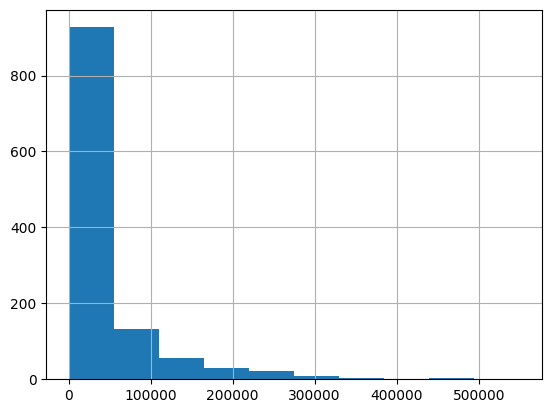

In [150]:
lfs_df.groupby(['Province', 'ASPBI Sector'])['PUFPWGTPRV'].sum().hist()

In [ ]:
41,527.193377

(14, 686.00845)

# 2. EDA

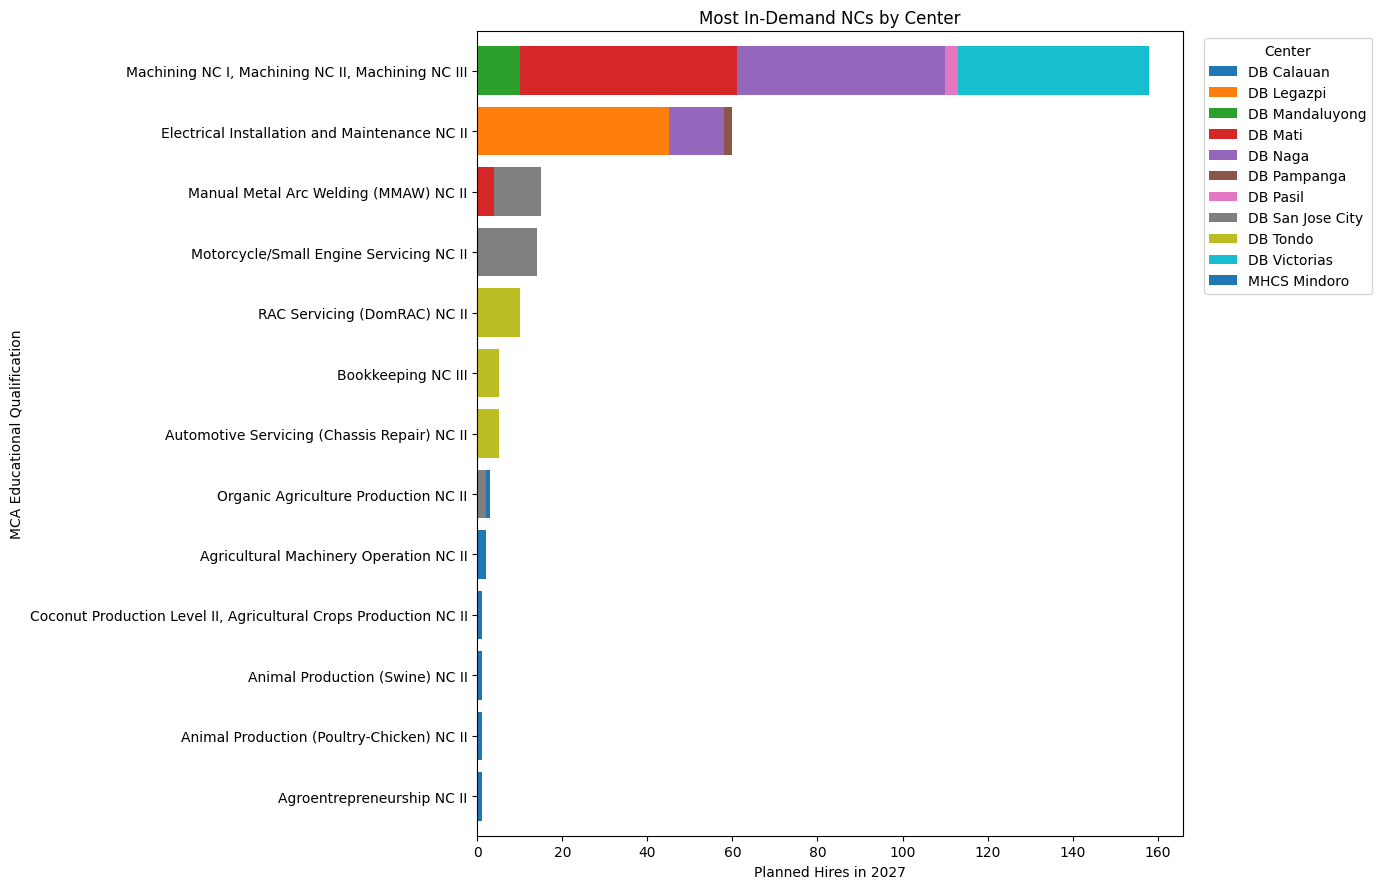

In [115]:
# Aggregate planned hires by NC and center
nc_demand = (
    db1_tvet_expanded_df
    .groupby(
        ["MCA Educational Qualification", "Center"]
    )["Planned 2027"]
    .sum()
    .unstack(fill_value=0)
)

# Sort NCs by total demand
nc_demand = nc_demand.loc[
    nc_demand.sum(axis=1).sort_values(ascending=True).index
]

fig, ax = plt.subplots(figsize=(14, 9))

nc_demand.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.8,
)

ax.set_title("Most In-Demand NCs by Center")
ax.set_xlabel("Planned Hires in 2027")
ax.set_ylabel("MCA Educational Qualification")

ax.legend(
    title="Center",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

In [136]:
# Aggregate planned hires by NC and center
nc_demand = (
    db1_tvet_expanded_df
    .groupby(
        "Center"
    )["Planned 2027"]
    .sum()
)

# Sort NCs by total demand
nc_demand = nc_demand.loc[
    nc_demand.sum(axis=1).sort_values(ascending=True).index
]

fig, ax = plt.subplots(figsize=(14, 9))

nc_demand.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.8,
)

ax.set_title("Most In-Demand NCs by Center")
ax.set_xlabel("Planned Hires in 2027")
ax.set_ylabel("MCA Educational Qualification")

ax.legend(
    title="Center",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

ValueError: No axis named 1 for object type Series

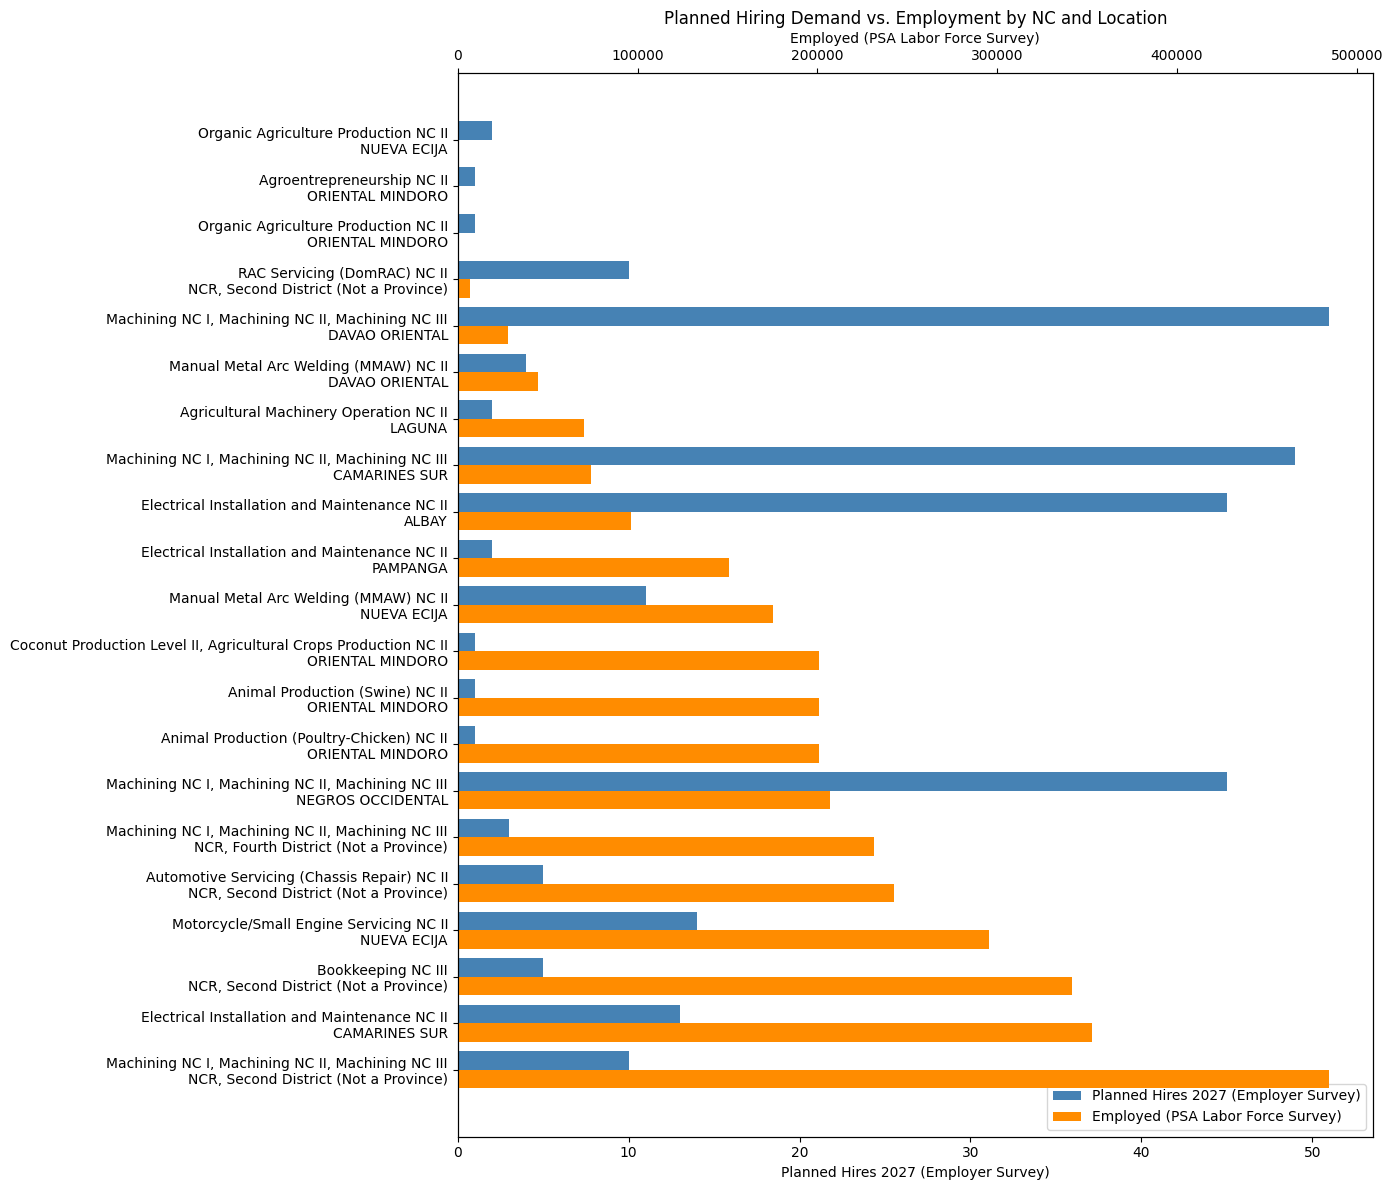

In [ ]:
# Aggregate hiring and labor market data by NC and province
location_demand = (
    db1_tvet_expanded_df
    .groupby(
        [
            "MCA Educational Qualification",
            "Training Center Province",
        ]
    )[
        ["Planned 2027", "Employed"]
    ]
    .sum()
    .reset_index()
)

# Remove combinations without demand or employment
location_demand = location_demand[
    (location_demand["Planned 2027"] > 0)
    | (location_demand["Employed"] > 0)
].copy()

# Calculate absolute difference between planned hires and employment
location_demand["Difference"] = (
    location_demand["Planned 2027"] - location_demand["Employed"]
)

# Sort from largest to smallest difference
location_demand = location_demand.sort_values(
    "Difference",
    ascending=False,
).reset_index(drop=True)

# Create labels
location_demand["NC - Location"] = (
    location_demand["MCA Educational Qualification"]
    + "\n"
    + location_demand["Training Center Province"]
)

x = range(len(location_demand))
width = 0.4

fig, ax1 = plt.subplots(figsize=(14, 12))
ax2 = ax1.twiny()

y = range(len(location_demand))
height = 0.4

# Planned hires from employer survey
ax1.barh(
    [i - height / 2 for i in y],
    location_demand["Planned 2027"],
    height=height,
    color="steelblue",
    label="Planned Hires 2027 (Employer Survey)",
)

# Employed population from PSA Labor Force Survey
ax2.barh(
    [i + height / 2 for i in y],
    location_demand["Employed"],
    height=height,
    color="darkorange",
    label="Employed (PSA Labor Force Survey)",
)

ax1.set_yticks(list(y))
ax1.set_yticklabels(location_demand["NC - Location"])

ax1.set_xlabel("Planned Hires 2027 (Employer Survey)")
ax2.set_xlabel("Employed (PSA Labor Force Survey)") 

ax1.set_title(
    "Planned Hiring Demand vs. Employment by NC and Location"
)

# Reverse order so largest differences appear at the top
ax1.invert_yaxis()

# Combine legends
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="lower right",
)

plt.tight_layout()
plt.show()

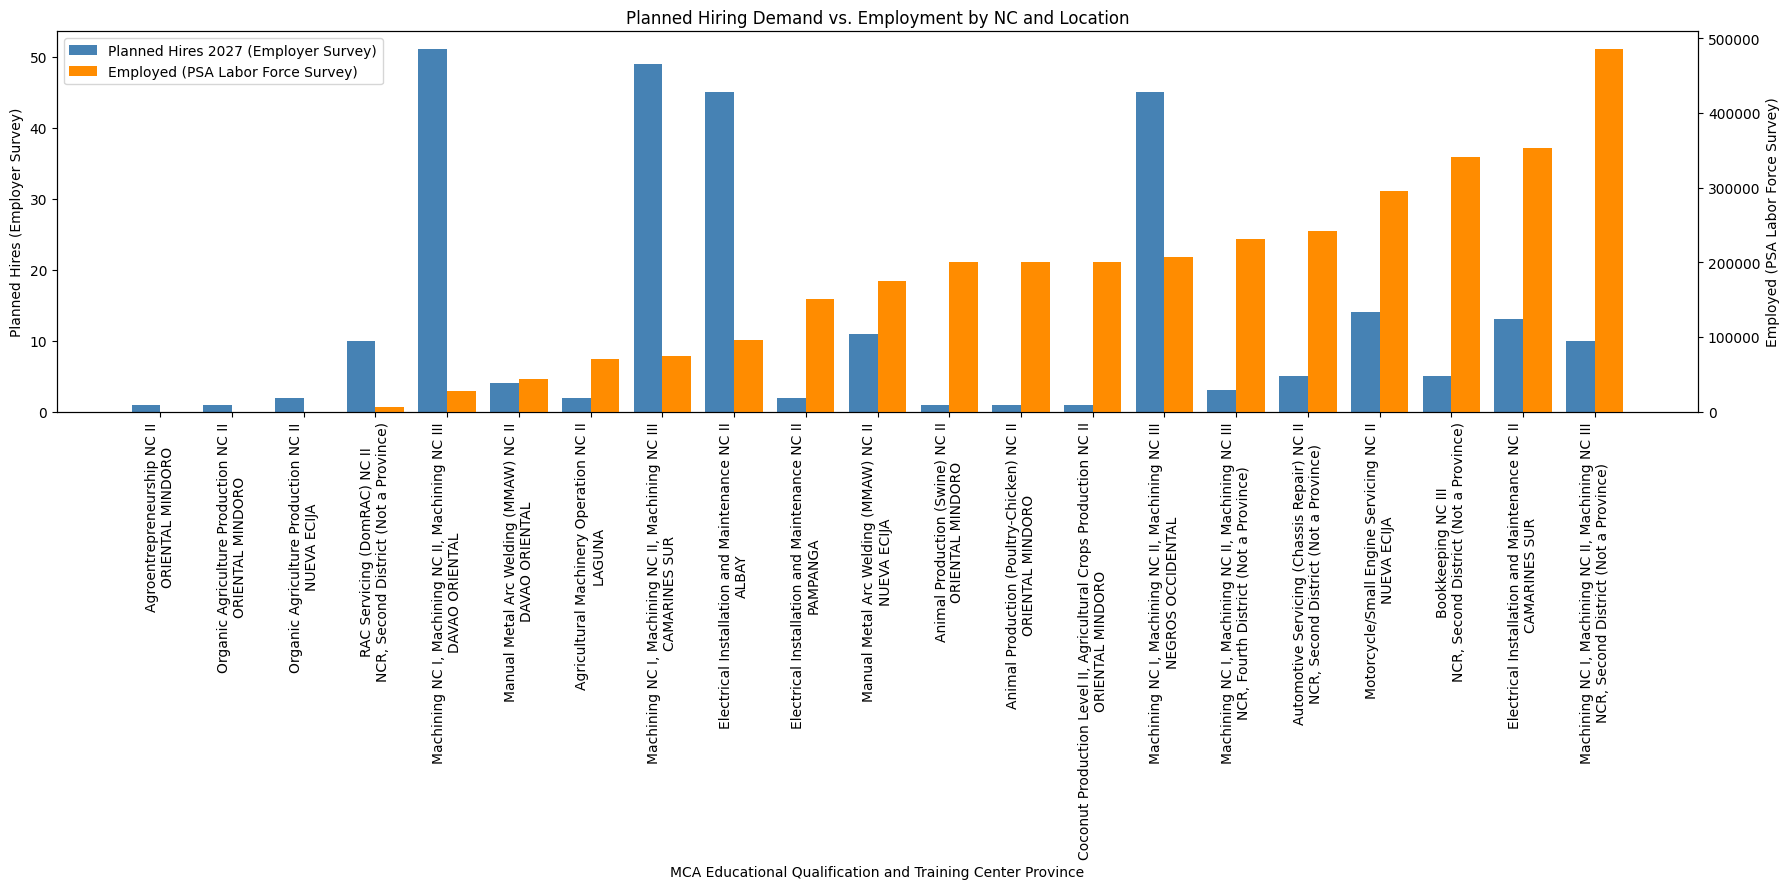

In [130]:
# Aggregate hiring and labor market data by NC and province
location_demand = (
    db1_tvet_expanded_df
    .groupby(
        [
            "MCA Educational Qualification",
            "Training Center Province",
        ]
    )[
        ["Planned 2027", "Employed"]
    ]
    .sum()
    .reset_index()
)

# Remove combinations without demand or employment
location_demand = location_demand[
    (location_demand["Planned 2027"] > 0)
    | (location_demand["Employed"] > 0)
].copy()

# Calculate absolute difference between planned hires and employment
location_demand["Difference"] = (
    location_demand["Planned 2027"] - location_demand["Employed"]
).abs()

# Sort from largest to smallest difference
location_demand = location_demand.sort_values(
    "Difference",
    ascending=True,
).reset_index(drop=True)

# Create labels
location_demand["NC - Location"] = (
    location_demand["MCA Educational Qualification"]
    + "\n"
    + location_demand["Training Center Province"]
)

x = range(len(location_demand))
width = 0.4

fig, ax1 = plt.subplots(figsize=(18, 9))
ax2 = ax1.twinx()

# Planned hires from employer survey
ax1.bar(
    [i - width / 2 for i in x],
    location_demand["Planned 2027"],
    width=width,
    color="steelblue",
    label="Planned Hires 2027 (Employer Survey)",
)

# Employed population from PSA Labor Force Survey
ax2.bar(
    [i + width / 2 for i in x],
    location_demand["Employed"],
    width=width,
    color="darkorange",
    label="Employed (PSA Labor Force Survey)",
)

ax1.set_xticks(list(x))
ax1.set_xticklabels(
    location_demand["NC - Location"],
    rotation=90,
)

ax1.set_xlabel("MCA Educational Qualification and Training Center Province")
ax1.set_ylabel("Planned Hires (Employer Survey)")
ax2.set_ylabel("Employed (PSA Labor Force Survey)")

ax1.set_title(
    "Planned Hiring Demand vs. Employment by NC and Location"
)

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper left",
)

plt.tight_layout()
plt.show()

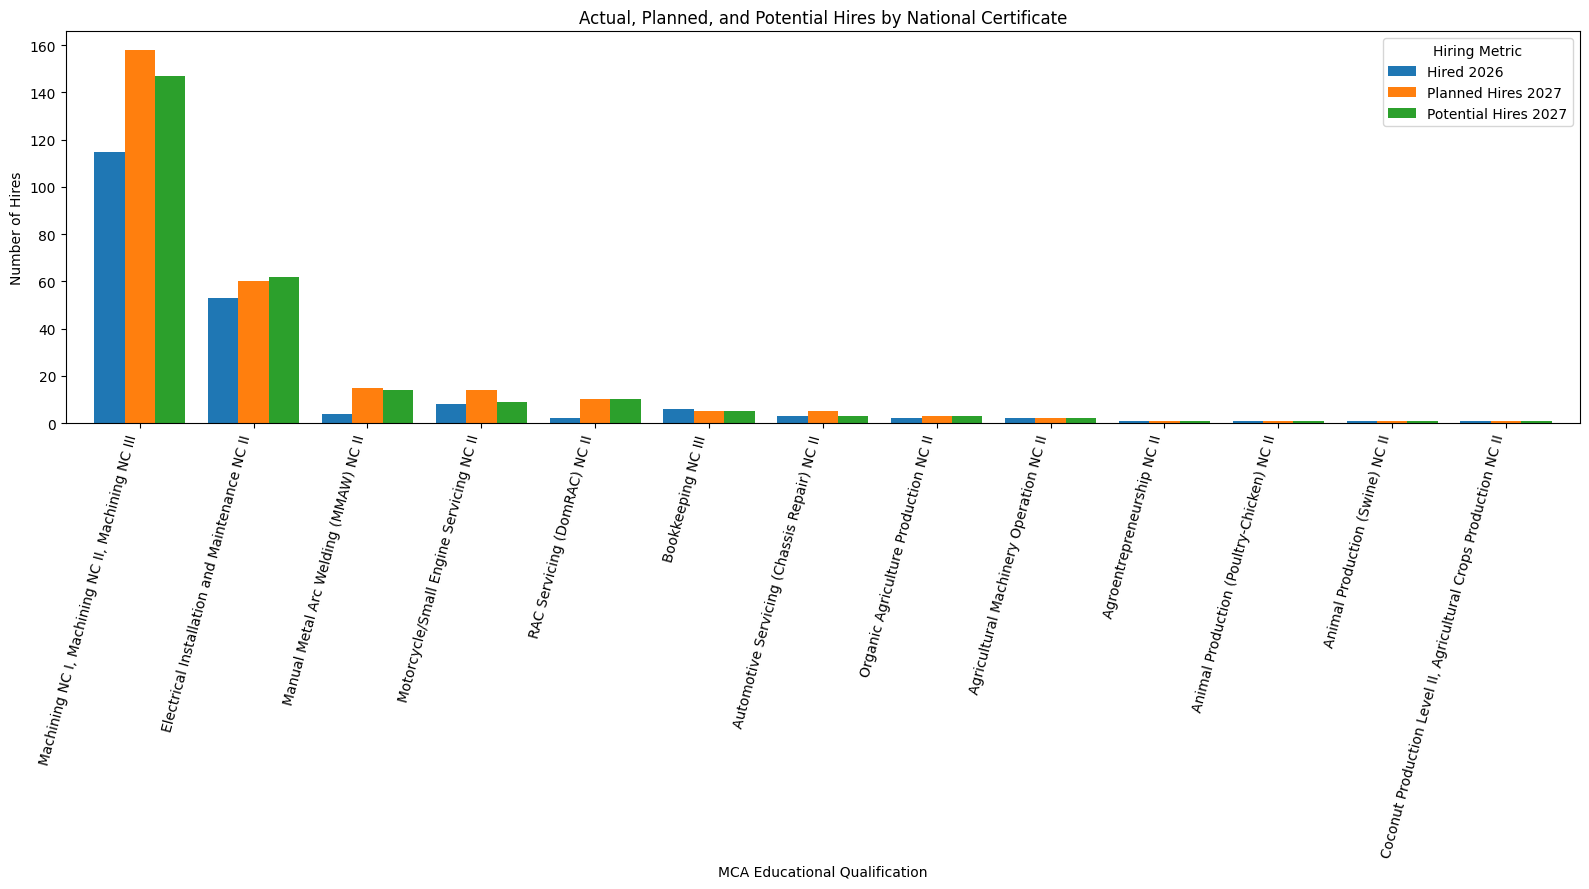

In [117]:
# Aggregate hiring metrics by NC
nc_hiring = (
    db1_tvet_expanded_df
    .groupby("MCA Educational Qualification")[
        [
            "Hired 2026",
            "Planned 2027",
            "From Center 2027",
        ]
    ]
    .sum()
)

# Sort by total hiring figures
nc_hiring = nc_hiring.loc[
    nc_hiring.sum(axis=1).sort_values(ascending=False).index
]

fig, ax = plt.subplots(figsize=(16, 9))

nc_hiring.plot(
    kind="bar",
    ax=ax,
    width=0.8,
)

ax.set_title(
    "Actual, Planned, and Potential Hires by National Certificate"
)
ax.set_xlabel("MCA Educational Qualification")
ax.set_ylabel("Number of Hires")

ax.legend(
    title="Hiring Metric",
    labels=[
        "Hired 2026",
        "Planned Hires 2027",
        "Potential Hires 2027",
    ],
)

plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()